# Named Entity Recognition (NER) System — End-to-End Sequence Labeling

**Objective:** Build a sequence labeling system on **CoNLL-2003** (IOB2 tagging: `PER`, `ORG`, `LOC`, `MISC`) comparing 4 architectures:
1. **LSTM** (GloVe 100d + Char-CNN for OOV handling)
2. **BiLSTM** (GloVe 100d + Char-CNN)
3. **BiLSTM + CRF** (GloVe 100d + Char-CNN + Conditional Random Field with Viterbi decoding)
4. **Fine-tuned BERT (`bert-base-cased`)** via HuggingFace `AutoModelForTokenClassification` & `Trainer` API

Evaluated with **`seqeval`** per-entity-type Precision, Recall, and F1, plus **color-coded real-time entity span visualization** and **CRF boundary analysis**.


## 0. Environment Setup


In [1]:
!pip -q install -U transformers datasets accelerate seqeval pytorch-crf gensim matplotlib seaborn pandas


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import json
import os
import random
import shutil
import warnings
from collections import Counter
from pathlib import Path

import gensim.downloader as api
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from datasets import load_dataset
from IPython.display import HTML, display
from seqeval.metrics import classification_report as seqeval_report
from seqeval.metrics import f1_score as seqeval_f1
from seqeval.metrics import precision_score as seqeval_precision
from seqeval.metrics import recall_score as seqeval_recall
from torch.utils.data import DataLoader, Dataset as TorchDataset
from torchcrf import CRF

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


PyTorch: 2.14.1+cu130 | Device: cuda
GPU: Tesla T4


## 1. Load & Explore CoNLL-2003 Dataset (IOB2 Tagging)


In [3]:
# Load CoNLL-2003 from Parquet mirror (works cleanly on all HuggingFace datasets versions)
try:
    dataset = load_dataset("lhoestq/conll2003")
except Exception:
    dataset = load_dataset("eriktks/conll2003", trust_remote_code=True)

print(dataset)

LABEL_LIST = ["O", "B-PER", "I-PER", "B-ORG", "I-ORG", "B-LOC", "I-LOC", "B-MISC", "I-MISC"]
ID2LABEL = {i: lbl for i, lbl in enumerate(LABEL_LIST)}
LABEL2ID = {lbl: i for i, lbl in enumerate(LABEL_LIST)}
NUM_LABELS = len(LABEL_LIST)

print("IOB2 Labels:", LABEL_LIST)
print("\nSample sentence:")
sample = dataset["train"][0]
for tok, tag_id in zip(sample["tokens"], sample["ner_tags"]):
    print(f"  {tok:15s} -> {ID2LABEL[tag_id]}")


dataset_infos.json:   0%|          | 0.00/3.67k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.07MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  281kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  259kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/14041 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3250 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['id', 'tokens', 'pos_tags', 'chunk_tags', 'ner_tags'],
        num_rows: 3453
    })
})
IOB2 Labels: ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']

Sample sentence:
  EU              -> B-ORG
  rejects         -> O
  German          -> B-MISC
  call            -> O
  to              -> O
  boycott         -> O
  British         -> B-MISC
  lamb            -> O
  .               -> O


,Entity Type,Train Count
0,LOC,7140
1,PER,6600
2,ORG,6321
3,MISC,3438


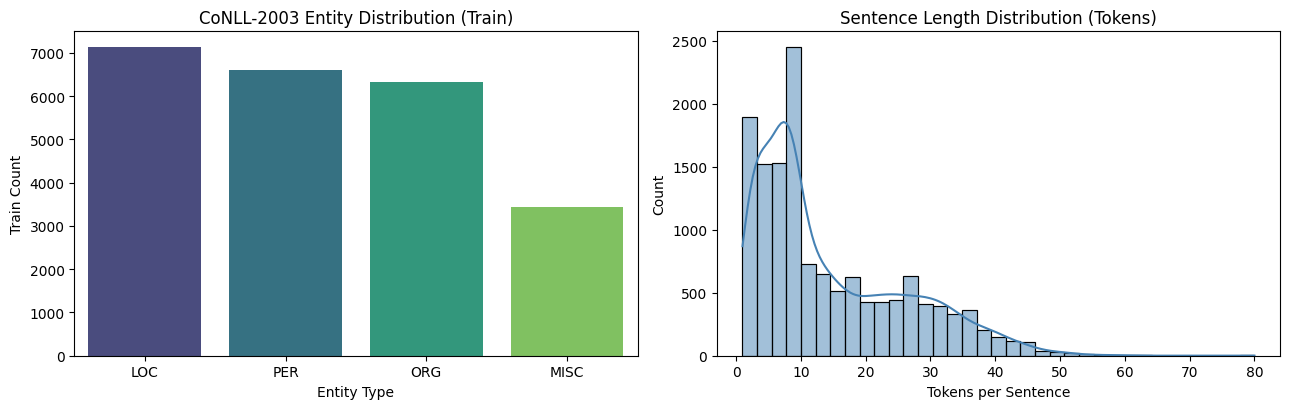

In [4]:
# Explore entity distribution and sentence lengths
entity_counts = Counter()
sent_lengths = []
for ex in dataset["train"]:
    sent_lengths.append(len(ex["tokens"]))
    for tid in ex["ner_tags"]:
        lbl = ID2LABEL[tid]
        if lbl.startswith("B-"):
            entity_counts[lbl[2:]] += 1

ent_df = pd.DataFrame(entity_counts.most_common(), columns=["Entity Type", "Train Count"])
display(ent_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(data=ent_df, x="Entity Type", y="Train Count", palette="viridis", ax=axes[0])
axes[0].set_title("CoNLL-2003 Entity Distribution (Train)")

sns.histplot(np.clip(sent_lengths, 0, 80), bins=35, kde=True, color="steelblue", ax=axes[1])
axes[1].set_title("Sentence Length Distribution (Tokens)")
axes[1].set_xlabel("Tokens per Sentence")
plt.tight_layout()
plt.show()


## 2. Vocabulary, Character Embeddings (OOV Handling) & Pre-trained GloVe 100d


In [5]:
# Build word & character vocabularies from training split
word_freq = Counter(w.lower() for ex in dataset["train"] for w in ex["tokens"])
WORD2IDX = {"<PAD>": 0, "<UNK>": 1}
for w, c in word_freq.items():
    if c >= 1:
        WORD2IDX[w] = len(WORD2IDX)

CHAR2IDX = {"<PAD>": 0, "<UNK>": 1}
for ex in dataset["train"]:
    for w in ex["tokens"]:
        for ch in w:
            if ch not in CHAR2IDX:
                CHAR2IDX[ch] = len(CHAR2IDX)

print(f"Word vocab size: {len(WORD2IDX)} | Char vocab size: {len(CHAR2IDX)}")

# Check OOV rate on test split (why Char-CNN is essential!)
test_tokens = [w.lower() for ex in dataset["test"] for w in ex["tokens"]]
oov_rate = sum(1 for w in test_tokens if w not in WORD2IDX) / len(test_tokens)
print(f"Test set OOV token rate: {oov_rate * 100:.2f}%")

# Load GloVe 100d via gensim
EMBED_DIM = 100
print("Loading GloVe 100d via gensim...")
glove = api.load("glove-wiki-gigaword-100")

embedding_matrix = np.random.normal(0, 0.05, (len(WORD2IDX), EMBED_DIM)).astype("float32")
embedding_matrix[0] = 0.0
hits = 0
for w, idx in WORD2IDX.items():
    if w in glove:
        embedding_matrix[idx] = glove[w]
        hits += 1
print(f"GloVe coverage: {hits}/{len(WORD2IDX)} ({hits / len(WORD2IDX) * 100:.1f}%)")


Word vocab size: 21011 | Char vocab size: 86
Test set OOV token rate: 10.87%
Loading GloVe 100d via gensim...
[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe coverage: 18415/21011 (87.6%)


In [6]:
MAX_WORD_LEN = 20


class NERDataset(TorchDataset):
    def __init__(self, hf_split):
        self.samples = hf_split

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        tokens = self.samples[idx]["tokens"]
        tags = self.samples[idx]["ner_tags"]
        w_ids = [WORD2IDX.get(w.lower(), 1) for w in tokens]
        c_ids = [
            [CHAR2IDX.get(ch, 1) for ch in w[:MAX_WORD_LEN]] + [0] * max(0, MAX_WORD_LEN - len(w))
            for w in tokens
        ]
        return w_ids, c_ids, tags


def collate_ner(batch):
    max_len = max(len(x[0]) for x in batch)
    bsz = len(batch)
    w_pad = torch.zeros((bsz, max_len), dtype=torch.long)
    c_pad = torch.zeros((bsz, max_len, MAX_WORD_LEN), dtype=torch.long)
    t_pad = torch.zeros((bsz, max_len), dtype=torch.long)
    mask = torch.zeros((bsz, max_len), dtype=torch.bool)

    for i, (w_ids, c_ids, tags) in enumerate(batch):
        L = len(w_ids)
        w_pad[i, :L] = torch.tensor(w_ids, dtype=torch.long)
        c_pad[i, :L] = torch.tensor(c_ids, dtype=torch.long)
        t_pad[i, :L] = torch.tensor(tags, dtype=torch.long)
        mask[i, :L] = True
    return w_pad, c_pad, t_pad, mask


train_loader = DataLoader(NERDataset(dataset["train"]), batch_size=64, shuffle=True, collate_fn=collate_ner)
val_loader = DataLoader(NERDataset(dataset["validation"]), batch_size=64, shuffle=False, collate_fn=collate_ner)
test_loader = DataLoader(NERDataset(dataset["test"]), batch_size=64, shuffle=False, collate_fn=collate_ner)


## 3. Build & Train 3 Custom Architectures: LSTM, BiLSTM, BiLSTM + CRF


In [7]:
class CharCNN(nn.Module):
    """Character-level CNN to generate morphological embeddings for OOV words."""

    def __init__(self, num_chars: int, char_emb_dim: int = 30, out_channels: int = 32):
        super().__init__()
        self.emb = nn.Embedding(num_chars, char_emb_dim, padding_idx=0)
        self.conv = nn.Conv1d(char_emb_dim, out_channels, kernel_size=3, padding=1)

    def forward(self, char_ids):
        # char_ids: (B, T, W)
        B, T, W = char_ids.shape
        x = self.emb(char_ids.view(B * T, W)).transpose(1, 2)  # (B*T, C, W)
        x = torch.relu(self.conv(x))
        x = x.max(dim=2).values  # (B*T, out_channels)
        return x.view(B, T, -1)


class SequenceNERModel(nn.Module):
    def __init__(self, arch: str, pretrained_emb: np.ndarray, num_chars: int, num_labels: int, hidden_dim: int = 128):
        super().__init__()
        self.arch = arch
        self.use_crf = (arch == "BiLSTM+CRF")
        bidirectional = arch in ("BiLSTM", "BiLSTM+CRF")

        self.word_emb = nn.Embedding.from_pretrained(torch.tensor(pretrained_emb), freeze=False, padding_idx=0)
        self.char_cnn = CharCNN(num_chars, char_emb_dim=30, out_channels=32)
        self.dropout = nn.Dropout(0.35)

        input_dim = pretrained_emb.shape[1] + 32
        self.lstm = nn.LSTM(
            input_dim,
            hidden_dim,
            num_layers=1,
            batch_first=True,
            bidirectional=bidirectional,
        )
        out_dim = hidden_dim * 2 if bidirectional else hidden_dim
        self.fc = nn.Linear(out_dim, num_labels)
        if self.use_crf:
            self.crf = CRF(num_labels, batch_first=True)

    def _emissions(self, w_ids, c_ids):
        w_e = self.word_emb(w_ids)
        c_e = self.char_cnn(c_ids)
        x = self.dropout(torch.cat([w_e, c_e], dim=-1))
        h, _ = self.lstm(x)
        return self.fc(self.dropout(h))

    def forward(self, w_ids, c_ids, mask, tags=None):
        emissions = self._emissions(w_ids, c_ids)
        if self.use_crf:
            if tags is not None:
                return -self.crf(emissions, tags, mask=mask, reduction="mean")
            return self.crf.decode(emissions, mask=mask)
        else:
            if tags is not None:
                loss_fn = nn.CrossEntropyLoss(reduction="none")
                loss = loss_fn(emissions.view(-1, emissions.size(-1)), tags.view(-1))
                mask_f = mask.view(-1).float()
                return (loss * mask_f).sum() / mask_f.sum()
            preds = emissions.argmax(dim=-1)
            return [preds[i, : mask[i].sum()].tolist() for i in range(preds.size(0))]


def evaluate_rnn(model, loader):
    model.eval()
    y_true, y_pred = [], []
    with torch.no_grad():
        for w_ids, c_ids, tags, mask in loader:
            w_ids, c_ids, mask = w_ids.to(DEVICE), c_ids.to(DEVICE), mask.to(DEVICE)
            preds = model(w_ids, c_ids, mask)
            for i, p_seq in enumerate(preds):
                L = int(mask[i].sum().item())
                t_seq = tags[i, :L].tolist()
                y_true.append([ID2LABEL[t] for t in t_seq])
                y_pred.append([ID2LABEL[p] for p in p_seq])
    return y_true, y_pred


def train_rnn(arch: str, epochs: int = 8, lr: float = 2e-3):
    print(f"\n{'='*60}\nTraining {arch}...\n{'='*60}")
    model = SequenceNERModel(arch, embedding_matrix, len(CHAR2IDX), NUM_LABELS).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    best_f1, best_state = -1.0, None

    for ep in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for w_ids, c_ids, tags, mask in train_loader:
            w_ids, c_ids, tags, mask = w_ids.to(DEVICE), c_ids.to(DEVICE), tags.to(DEVICE), mask.to(DEVICE)
            optimizer.zero_grad()
            loss = model(w_ids, c_ids, mask, tags=tags)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            total_loss += loss.item()

        vt, vp = evaluate_rnn(model, val_loader)
        vf1 = seqeval_f1(vt, vp)
        print(f"Epoch {ep}/{epochs} | Loss: {total_loss/len(train_loader):.4f} | Val F1: {vf1:.4f}")
        if vf1 > best_f1:
            best_f1 = vf1
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state)
    return model


rnn_models = {}
all_test_preds = {}
y_true_test = None

for arch in ["LSTM", "BiLSTM", "BiLSTM+CRF"]:
    m = train_rnn(arch, epochs=8)
    rnn_models[arch] = m
    yt, yp = evaluate_rnn(m, test_loader)
    y_true_test = yt
    all_test_preds[arch] = yp



Training LSTM...
Epoch 1/8 | Loss: 0.4166 | Val F1: 0.7447
Epoch 2/8 | Loss: 0.1309 | Val F1: 0.7926
Epoch 3/8 | Loss: 0.0913 | Val F1: 0.8182
Epoch 4/8 | Loss: 0.0715 | Val F1: 0.8200
Epoch 5/8 | Loss: 0.0600 | Val F1: 0.8288
Epoch 6/8 | Loss: 0.0512 | Val F1: 0.8284
Epoch 7/8 | Loss: 0.0440 | Val F1: 0.8340
Epoch 8/8 | Loss: 0.0394 | Val F1: 0.8259

Training BiLSTM...
Epoch 1/8 | Loss: 0.3451 | Val F1: 0.8107
Epoch 2/8 | Loss: 0.0987 | Val F1: 0.8666
Epoch 3/8 | Loss: 0.0606 | Val F1: 0.8842
Epoch 4/8 | Loss: 0.0426 | Val F1: 0.8816
Epoch 5/8 | Loss: 0.0329 | Val F1: 0.8914
Epoch 6/8 | Loss: 0.0257 | Val F1: 0.9004
Epoch 7/8 | Loss: 0.0207 | Val F1: 0.9043
Epoch 8/8 | Loss: 0.0173 | Val F1: 0.9027

Training BiLSTM+CRF...
Epoch 1/8 | Loss: 4.0353 | Val F1: 0.8590
Epoch 2/8 | Loss: 1.0922 | Val F1: 0.8803
Epoch 3/8 | Loss: 0.6824 | Val F1: 0.9075
Epoch 4/8 | Loss: 0.4831 | Val F1: 0.9066
Epoch 5/8 | Loss: 0.3575 | Val F1: 0.9167
Epoch 6/8 | Loss: 0.2589 | Val F1: 0.9142
Epoch 7/8 | Lo

## 4. Fine-Tune BERT (`bert-base-cased`) for Token Classification (HuggingFace Trainer)


In [8]:
from transformers import (
    AutoModelForTokenClassification,
    AutoTokenizer,
    DataCollatorForTokenClassification,
    Trainer,
    TrainingArguments,
)

BERT_NAME = "bert-base-cased"
hf_tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)


def tokenize_and_align_labels(examples):
    tokenized = hf_tokenizer(examples["tokens"], truncation=True, is_split_into_words=True)
    aligned_labels = []
    for i, label_seq in enumerate(examples["ner_tags"]):
        word_ids = tokenized.word_ids(batch_index=i)
        prev_wid = None
        label_ids = []
        for wid in word_ids:
            if wid is None:
                label_ids.append(-100)
            elif wid != prev_wid:
                label_ids.append(label_seq[wid])
            else:
                label_ids.append(-100)  # ignore subword continuations in loss
            prev_wid = wid
        aligned_labels.append(label_ids)
    tokenized["labels"] = aligned_labels
    return tokenized


tokenized_ds = dataset.map(tokenize_and_align_labels, batched=True)


def compute_ner_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    true_seqs, pred_seqs = [], []
    for p_row, l_row in zip(preds, labels):
        t_seq, p_seq = [], []
        for p, l in zip(p_row, l_row):
            if l != -100:
                t_seq.append(ID2LABEL[l])
                p_seq.append(ID2LABEL[p])
        true_seqs.append(t_seq)
        pred_seqs.append(p_seq)
    return {
        "precision": seqeval_precision(true_seqs, pred_seqs),
        "recall": seqeval_recall(true_seqs, pred_seqs),
        "f1": seqeval_f1(true_seqs, pred_seqs),
    }


hf_model = AutoModelForTokenClassification.from_pretrained(
    BERT_NAME,
    num_labels=NUM_LABELS,
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)

training_args = TrainingArguments(
    output_dir="./bert_ner_ckpts",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

trainer = Trainer(
    model=hf_model,
    args=training_args,
    train_dataset=tokenized_ds["train"],
    eval_dataset=tokenized_ds["validation"],
    processing_class=hf_tokenizer,
    data_collator=DataCollatorForTokenClassification(hf_tokenizer),
    compute_metrics=compute_ner_metrics,
)

trainer.train()

# Extract aligned test predictions for seqeval comparison
raw_pred = trainer.predict(tokenized_ds["test"])
bert_preds_idx = np.argmax(raw_pred.predictions, axis=-1)
bert_pred_seqs = []
for p_row, l_row in zip(bert_preds_idx, raw_pred.label_ids):
    bert_pred_seqs.append([ID2LABEL[p] for p, l in zip(p_row, l_row) if l != -100])

all_test_preds["BERT-base-cased"] = bert_pred_seqs


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

... (6 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.atte

## 5. Seqeval Evaluation, 4-Model Comparison & CRF Boundary Analysis


,Model,Precision,Recall,F1-Score
0,BERT-base-cased,0.9065,0.9216,0.9140
1,BiLSTM+CRF,0.8664,0.8575,0.8619
2,BiLSTM,0.8336,0.8435,0.8385
3,LSTM,0.7458,0.7645,0.7550


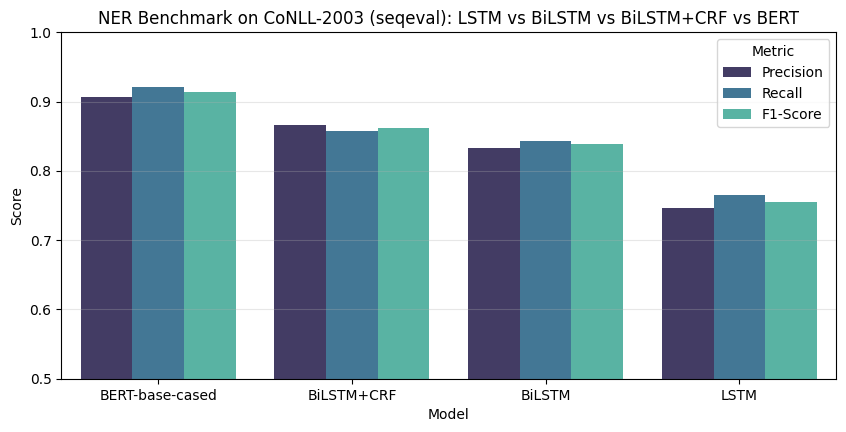


Best Model: BERT-base-cased

              precision    recall  f1-score   support

         LOC     0.9315    0.9376    0.9346      1668
        MISC     0.7795    0.8362    0.8069       702
         ORG     0.8840    0.9043    0.8940      1661
         PER     0.9634    0.9598    0.9616      1617

   micro avg     0.9065    0.9216    0.9140      5648
   macro avg     0.8896    0.9095    0.8993      5648
weighted avg     0.9078    0.9216    0.9145      5648



In [9]:
rows = []
for name, preds in all_test_preds.items():
    rows.append({
        "Model": name,
        "Precision": round(seqeval_precision(y_true_test, preds), 4),
        "Recall": round(seqeval_recall(y_true_test, preds), 4),
        "F1-Score": round(seqeval_f1(y_true_test, preds), 4),
    })

results_df = pd.DataFrame(rows).sort_values(by="F1-Score", ascending=False).reset_index(drop=True)
display(results_df)

plot_df = results_df.melt(id_vars="Model", value_vars=["Precision", "Recall", "F1-Score"], var_name="Metric", value_name="Score")
plt.figure(figsize=(10, 4.5))
sns.barplot(data=plot_df, x="Model", y="Score", hue="Metric", palette="mako")
plt.ylim(0.5, 1.0)
plt.title("NER Benchmark on CoNLL-2003 (seqeval): LSTM vs BiLSTM vs BiLSTM+CRF vs BERT")
plt.grid(axis="y", alpha=0.3)
plt.show()

best_model_name = results_df.iloc[0]["Model"]
print(f"\nBest Model: {best_model_name}\n")
print(seqeval_report(y_true_test, all_test_preds[best_model_name], digits=4))


In [10]:
# Quantify illegal IOB transitions (e.g., O -> I-ORG or B-PER -> I-LOC) fixed by CRF!
def count_illegal_iob(pred_seqs):
    illegal = 0
    for seq in pred_seqs:
        prev = "O"
        for tag in seq:
            if tag.startswith("I-"):
                ent = tag[2:]
                if prev == "O" or prev[2:] != ent:
                    illegal += 1
            prev = tag
    return illegal

for name in ["LSTM", "BiLSTM", "BiLSTM+CRF", "BERT-base-cased"]:
    print(f"{name:16s} | Illegal IOB transitions on Test Set: {count_illegal_iob(all_test_preds[name])}")


LSTM             | Illegal IOB transitions on Test Set: 392
BiLSTM           | Illegal IOB transitions on Test Set: 169
BiLSTM+CRF       | Illegal IOB transitions on Test Set: 17
BERT-base-cased  | Illegal IOB transitions on Test Set: 43


## 6. Real-Time Color-Coded Entity Span Visualization


In [11]:
from transformers import pipeline

ner_pipe = pipeline(
    "token-classification",
    model=hf_model,
    tokenizer=hf_tokenizer,
    aggregation_strategy="simple",
    device=0 if torch.cuda.is_available() else -1,
)

ENTITY_COLORS = {
    "PER": ("#2563EB", "#DBEAFE"),
    "ORG": ("#7C3AED", "#EDE9FE"),
    "LOC": ("#059669", "#D1FAE5"),
    "MISC": ("#D97706", "#FEF3C7"),
}


def visualize_ner(text: str):
    entities = ner_pipe(text)
    html_parts = []
    last_end = 0
    for ent in entities:
        start, end = ent["start"], ent["end"]
        grp = ent["entity_group"]
        fg, bg = ENTITY_COLORS.get(grp, ("#334155", "#E2E8F0"))
        html_parts.append(text[last_end:start])
        html_parts.append(
            f'<span style="background:{bg};color:{fg};padding:2px 7px;border-radius:6px;font-weight:600;border:1px solid {fg}44;">'
            f'{text[start:end]} <sup style="font-size:10px;opacity:0.85;">{grp}</sup></span>'
        )
        last_end = end
    html_parts.append(text[last_end:])
    display(HTML(f'<div style="font-size:16px;line-height:2.1;padding:12px 16px;border-radius:10px;background:#f8fafc;color:#0f172a;margin:8px 0;">{"".join(html_parts)}</div>'))


demo_sentences = [
    "Satya Nadella announced that Microsoft will open a new AI research center in Cairo next March.",
    "Lionel Messi scored twice for Inter Miami during their match in New York.",
    "Apple and Google are collaborating with European Union regulators in Brussels.",
]

for s in demo_sentences:
    visualize_ner(s)


## 7. Save Best Model & Results for Download


In [12]:
SAVE_DIR = Path("saved_ner_model")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

trainer.save_model(str(SAVE_DIR / "transformer"))
hf_tokenizer.save_pretrained(str(SAVE_DIR / "transformer"))
results_df.to_csv(SAVE_DIR / "model_comparison.csv", index=False)
(SAVE_DIR / "classification_report.txt").write_text(
    seqeval_report(y_true_test, all_test_preds[best_model_name], digits=4), encoding="utf-8"
)
(SAVE_DIR / "model_meta.json").write_text(
    json.dumps({"best_model": best_model_name, "labels": LABEL_LIST}, indent=2), encoding="utf-8"
)

zip_path = shutil.make_archive("ner_model_and_results", "zip", ".", "saved_ner_model")
print("Exported:", zip_path)
# Uncomment in Colab to download immediately:
# from google.colab import files; files.download(zip_path)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Exported: /content/ner_model_and_results.zip
